# 05 · Tweak ledger: every derived dose, next to the numbers it came from

A place to go through the buffs and nerfs by hand. For every numeric tweak this notebook shows
the old and new value of the number we picked, every size measure side by side, what *else*
the patch changed on that card, and (if notebook 02's saved fits are there) the measured
effect. It reads only the committed tables in `reference/`; the
effects section also reads `data/analysis/did_h3.parquet` if it exists.

**What the ledger is for.** The dose-response rests on one derived number per tweak, the *dose*. Think
of a shop's till roll: before you trust the daily total, you read the individual lines. Every
line here is one tweak, and you can check it against the patch notes yourself.

**Terms**
- *main field*: the one number on the card we chose to measure the change by (damage, block,
  energy gained, a power's amount, or a `vars.*` value when it is the only one that changed).
- *delta*: new − old. *pct*: percent change. *ln*: `ln(new/old)`, the dose used so far. All three
  are multiplied by `direction` (+1 means "a bigger number is a buff"), so a positive value
  is a buff and a negative one a nerf.
- *kind*: damage, block, power amount, or other (a grab-bag).
- *mirror fields*: the game stores many values twice, e.g. `damage` and `vars.Damage`. They
  are listed apart so each change is not counted twice.

Sections: 0 setup · 1 the ledger and its checks · 2 what else the patch changed ·
3 whether a bigger number is always a buff · 4 the rulers side by side · 5 effects next to doses ·
6 what the dose doesn't capture.

## 0. Setup

In [1]:
import os
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "reference").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

REF = ROOT / "reference"
OUT = ROOT / "data" / "analysis"          # git-ignored (data/)
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "lines.markersize": 4,
})
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 200,
              "display.max_colwidth", 80)
TREATED_C, CONTROL_C, GREY = "#e8702a", "#2a6fdb", "#555555"
KIND_C = {"damage": "#e8702a", "block": "#2a6fdb", "power amount": "#2a9d6f", "other": "#888888"}

TW = pd.read_csv(REF / "tweak_sizes.csv", dtype=str, keep_default_na=False).set_index("card_patch_id")
CPF = pd.read_csv(REF / "card_patch_fields.csv", dtype=str, keep_default_na=False)
print(f"{len(TW)} tweaks in tweak_sizes.csv; {len(CPF)} changed-field rows in card_patch_fields.csv")

50 tweaks in tweak_sizes.csv; 326 changed-field rows in card_patch_fields.csv


## 1. The ledger

One row per tweak (all 50, including the ones we cannot estimate). Columns:

- `patch`: which stable patch (first = v0.103.2, second = v0.107.1).
- `old`, `new`: the main field's values straight from the table.
- `delta`, `pct`, `ln`: three ways to size the same change. `pct` is in percent.
- `change`: buff or nerf by the sign of `ln`.
- `solo`: whether the tweak can be estimated from solo runs' card rewards (`no`: a colorless,
  Basic or Token card, or multiplayer-only). The `note` column says why.
- `mixed`: one number up and another down, so there is no single direction.
- `upg_only`: only the upgraded version changed, so no base number moved.

Sorted by patch, kind and `ln`. Read it as a spreadsheet and check each line against what you
know of the patch.

In [2]:
def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace("+", "", regex=False), errors="coerce")

def kind_of(field):
    if field == "damage":
        return "damage"
    if field == "block":
        return "block"
    if str(field).startswith("powers_applied"):
        return "power amount"
    if field == "":
        return ""
    return "other"          # Forge, energy_gain, ExtraDamage, Increase, ... (a grab-bag)

L = TW.copy()
for c in ["log_ratio", "upgraded_log_ratio", "direction"]:
    L[c] = pd.to_numeric(L[c], errors="coerce")
L["old_n"], L["new_n"] = to_num(L.old), to_num(L.new)
L["patch"] = np.where(L.before_builds == "v0.99.1", "first", "second")
L["kind"] = L.main_field.map(kind_of)
L["delta"] = L.direction * (L.new_n - L.old_n)
L["pct"] = 100 * L.direction * (L.new_n - L.old_n) / L.old_n
L["ln"] = L.direction * L.log_ratio
L["change"] = np.where(L.ln > 0, "buff", np.where(L.ln < 0, "nerf", ""))
L = L.rename(columns={"solo_estimable": "solo", "mixed_direction": "mixed", "upgrade_only": "upg_only"})

LEDGER_COLS = ["card_id", "color", "patch", "kind", "main_field", "old", "new", "delta", "pct", "ln",
               "change", "solo", "mixed", "upg_only", "note"]
L = L.sort_values(["patch", "kind", "ln"], ascending=[False, True, True])   # first patch on top
display(L[LEDGER_COLS].round(3))

,card_id,color,patch,kind,main_field,old,new,delta,pct,ln,change,solo,mixed,upg_only,note
card_patch_id,,,,,,,,,,,,,,,
ROYALTIES@v0.107.1/patch,ROYALTIES,regent,second,,,,,NaN,NaN,NaN,,yes,no,yes,upgrade-only: no base field changed; base value not in the change tables: no...
UNTOUCHABLE@v0.107.1/patch,UNTOUCHABLE,silent,second,,,,,NaN,NaN,NaN,,yes,no,yes,upgrade-only: no base field changed; upgraded ratio uses base block 6 (set b...
REFLECT@v0.107.1/patch,REFLECT,regent,second,block,block,17,15,-2.0,-11.765,-0.125,nerf,yes,yes,no,
MINION_SACRIFICE@v0.107.1/patch,MINION_SACRIFICE,token,second,block,block,9,8,-1.0,-11.111,-0.118,nerf,no,no,no,"not solo-estimable: rarity Token, color token"
PATTER@v0.107.1/patch,PATTER,regent,second,block,block,9,8,-1.0,-11.111,-0.118,nerf,yes,no,no,
BULWARK@v0.107.1/patch,BULWARK,regent,second,block,block,13,12,-1.0,-7.692,-0.080,nerf,yes,no,no,
HYPERBEAM@v0.107.1/patch,HYPERBEAM,defect,second,damage,damage,26,28,2.0,7.692,0.074,buff,yes,no,no,
POUNCE@v0.107.1/patch,POUNCE,silent,second,damage,damage,12,14,2.0,16.667,0.154,buff,yes,no,no,
SYNTHESIS@v0.107.1/patch,SYNTHESIS,defect,second,damage,damage,12,14,2.0,16.667,0.154,buff,yes,no,no,


### Checks on the derived columns

Four automatic checks. Anything flagged is worth a look before trusting a dose.

1. `ln` stored in the table against `direction × ln(new/old)` recomputed from `old` and `new`.
2. `delta`, `pct` and `ln` should always agree in sign.
3. `pct` against the independent `rel_change` column in `card_patch_fields.csv` (a second
   route to the same percent change).
4. How many tweaks fall in each estimability bucket.

In [3]:
rec = L.direction * np.log(L.new_n / L.old_n)
bad1 = L[(rec - L.ln).abs() > 1e-3]
print(f"1. stored ln vs recomputed: max |diff| = {(rec - L.ln).abs().max():.5f}; "
      f"{len(bad1)} rows differ by more than 0.001")
if len(bad1):
    display(bad1[["card_id", "patch", "main_field", "old", "new", "ln"]])

has = L.ln.notna()
bad2 = L[has & ~((np.sign(L.delta) == np.sign(L.ln)) & (np.sign(L.pct) == np.sign(L.ln)))]
print(f"2. sign disagreements among delta / pct / ln: {len(bad2)}")
if len(bad2):
    display(bad2[["card_id", "patch", "main_field", "old", "new", "delta", "pct", "ln"]])

rc = CPF[CPF.card_patch_id.isin(L.index)].copy()
rc["rel"] = pd.to_numeric(rc.rel_change, errors="coerce")
rc = rc.merge(L[["main_field", "pct"]].reset_index(), left_on=["card_patch_id", "field"],
              right_on=["card_patch_id", "main_field"])
rc["pct_from_rel"] = 100 * rc.rel
bad3 = rc[(rc.pct_from_rel.abs() - rc.pct.abs()).abs() > 0.5]
print(f"3. pct vs rel_change (card_patch_fields): compared {len(rc)} tweaks, "
      f"{len(bad3)} differ by more than 0.5 percentage points of change")
if len(bad3):
    display(bad3[["card_patch_id", "field", "old", "new", "rel_change", "pct"]])

print("4. buckets")
display(pd.crosstab([L.solo, L.mixed, L.upg_only], L.patch, margins=True))

1. stored ln vs recomputed: max |diff| = 0.00005; 0 rows differ by more than 0.001
2. sign disagreements among delta / pct / ln: 0
3. pct vs rel_change (card_patch_fields): compared 47 tweaks, 0 differ by more than 0.5 percentage points of change
4. buckets


patch                first  second  All
solo mixed upg_only                    
no   no    no            5       2    7
yes  no    no           24      14   38
           yes           1       2    3
     yes   no            1       1    2
All                     31      19   50

## 2. What else the patch changed on each card

The dose looks at one number. This table shows everything the patch changed on each card, taken
from `card_patch_fields.csv`, so you can see what we are *not* measuring.

- `changed`: base fields that changed, as `field old→new`. `upgrade.*` entries are changes to
  the upgraded card only.
- `mirrors`: the `vars.*` entries (often the same number stored a second way, but sometimes a
  different quantity, such as a power's name).

Flags (also in the last columns):

- `also_upgrade`: an `upgrade.*` field changed too, so the upgraded card changed as well as the base.
- `scaling_var`: `vars.CalculatedDamage` or `vars.CalculationBase` changed. These cards compute their
  damage from something else (a count, a stat), so the printed `damage` is a base value and the
  dose may mean something different there.
- `multi_field`: more than one non-upgrade, non-`vars` field changed.

In [4]:
CH = CPF[CPF.card_patch_id.isin(L.index)]

def summarize(g):
    base = [f"{r.field} {r.old}→{r.new}" for r in g.itertuples() if not r.field.startswith("vars.")]
    mirror = [f"{r.field} {r.old}→{r.new}" for r in g.itertuples() if r.field.startswith("vars.")]
    nonup = [r.field for r in g.itertuples()
             if not r.field.startswith("vars.") and not r.field.startswith("upgrade.")]
    return pd.Series(dict(
        changed=" | ".join(base), mirrors=" | ".join(mirror),
        also_upgrade=any(f.startswith("upgrade.") for f in g.field),
        scaling_var=any(f in ("vars.CalculatedDamage", "vars.CalculationBase") for f in g.field),
        multi_field=len(nonup) > 1))

S = CH.groupby("card_patch_id").apply(summarize)
LL = L.join(S)
for c in ["also_upgrade", "scaling_var", "multi_field"]:
    LL[c] = LL[c].fillna(False).astype(bool)
display(LL[["card_id", "patch", "kind", "ln", "change", "changed", "mirrors",
            "also_upgrade", "scaling_var", "multi_field"]].round(3))
print(f"{int(LL.also_upgrade.sum())} tweaks also changed the upgraded card, "
      f"{int(LL.scaling_var.sum())} have a scaling variable, {int(LL.multi_field.sum())} changed "
      f"more than one base field")

,card_id,patch,kind,ln,change,changed,mirrors,also_upgrade,scaling_var,multi_field
card_patch_id,,,,,,,,,,
ROYALTIES@v0.107.1/patch,ROYALTIES,second,,NaN,,upgrade.gold +5→+10,,True,False,False
UNTOUCHABLE@v0.107.1/patch,UNTOUCHABLE,second,,NaN,,upgrade.block +2→+3,,True,False,False
REFLECT@v0.107.1/patch,REFLECT,second,block,-0.125,nerf,block 17→15 | upgrade.block +4→+5,vars.Block 17→15,True,False,False
MINION_SACRIFICE@v0.107.1/patch,MINION_SACRIFICE,second,block,-0.118,nerf,block 9→8,vars.Block 9→8,False,False,False
PATTER@v0.107.1/patch,PATTER,second,block,-0.118,nerf,block 9→8,vars.Block 9→8,False,False,False
BULWARK@v0.107.1/patch,BULWARK,second,block,-0.080,nerf,block 13→12,vars.Block 13→12,False,False,False
HYPERBEAM@v0.107.1/patch,HYPERBEAM,second,damage,0.074,buff,damage 26→28,vars.Damage 26→28,False,False,False
POUNCE@v0.107.1/patch,POUNCE,second,damage,0.154,buff,damage 12→14,vars.Damage 12→14,False,False,False
SYNTHESIS@v0.107.1/patch,SYNTHESIS,second,damage,0.154,buff,damage 12→14,vars.Damage 12→14,False,False,False


14 tweaks also changed the upgraded card, 2 have a scaling variable, 0 changed more than one base field


## 3. Whether a bigger number is always a buff

`direction` is +1 on every one of the 50 rows, meaning the code treats a bigger main-field
number as better for the player everywhere. That is probably right for damage, block, energy
gained and most power amounts, but the table below lets you check each field. The `vars.*` fields
and `powers_applied` are the ones worth a look, because what the number means depends on the
card. For each, the check is whether the player benefits when this number goes up.

(The `mirrors` column in section 2 shows which power or variable a `powers_applied` change belongs
to, for instance `vars.Strength`.)

In [5]:
print("direction values in tweak_sizes.csv:", L.direction.value_counts(dropna=False).to_dict())
A = (L[L.main_field != ""].groupby("main_field")
       .agg(n=("card_id", "size"), kind=("kind", "first"),
            cards=("card_id", lambda s: ", ".join(sorted(set(s)))),
            n_buff=("change", lambda s: int((s == "buff").sum())),
            n_nerf=("change", lambda s: int((s == "nerf").sum())))
       .sort_values("n", ascending=False))
display(A)
print("tweaks with no main field:")
display(L[L.main_field == ""][["card_id", "patch", "note"]])

direction values in tweak_sizes.csv: {1: 50}


,n,kind,cards,n_buff,n_nerf
main_field,,,,,
damage,22,damage,"COLLISION_COURSE, CRESCENT_SPEAR, DEBILITATE, FALLING_STAR, FLICK_FLACK, GRA...",18,4
block,8,block,"BULWARK, GATHER_LIGHT, I_AM_INVINCIBLE, MINION_SACRIFICE, PATTER, REFLECT, U...",3,5
powers_applied[0].amount,8,power amount,"ANTICIPATE, DANSE_MACABRE, DEBILITATE, ETERNAL_ARMOR, FIGHT_ME, JUGGERNAUT, ...",6,2
vars.Forge,3,other,"FURNACE, REFINE_BLADE, WROUGHT_IN_WAR",3,0
energy_gain,1,other,BELIEVE_IN_YOU,0,1
vars.BlockNextTurn,1,other,GLITTERSTREAM,1,0
vars.CorrosiveWave,1,other,CORROSIVE_WAVE,0,1
vars.ExtraBlock,1,other,FASTEN,0,1
vars.ExtraDamage,1,other,DEATH_MARCH,1,0


tweaks with no main field:


,card_id,patch,note
card_patch_id,,,
ROYALTIES@v0.107.1/patch,ROYALTIES,second,upgrade-only: no base field changed; base value not in the change tables: no...
UNTOUCHABLE@v0.107.1/patch,UNTOUCHABLE,second,upgrade-only: no base field changed; upgraded ratio uses base block 6 (set b...
SERPENT_FORM@v0.103.2/patch,SERPENT_FORM,first,upgrade-only: no base field changed; base value not in the change tables: no...


## 4. The rulers side by side

For the tweaks that go onto the dose-response line (estimable, one direction, a base number
that changed), this ranks them by size under three rulers. The ranking is what matters for a
slope, since a bigger dose is supposed to mean a bigger effect.

- `rank_delta`, `rank_pct`, `rank_ln`: 1 = biggest |change| under that ruler.
- `gap`: `rank_delta − rank_ln`. Large and positive: the tweak looks big in absolute terms and small
  in log terms (typically +2 on a large number). Large and negative: the opposite.

The Spearman table is a summary of how much the rankings agree (1 = identical order). The plot in
the next cell shows where the rulers disagree most; labels are only drawn for
tweaks with |gap| of at least `GAP`.

In [6]:
R = L[(L.solo == "yes") & (L.mixed != "yes") & (L.upg_only != "yes") & L.ln.notna()].copy()
for c in ["delta", "pct", "ln"]:
    R["rank_" + c] = R[c].abs().rank(ascending=False, method="min")
R["gap"] = R.rank_delta - R.rank_ln
print(f"{len(R)} tweaks on the line ({int((R.patch == 'first').sum())} first, "
      f"{int((R.patch == 'second').sum())} second)")
print("Spearman rank correlation between rulers (by |change|):")
display(R[["delta", "pct", "ln"]].abs().corr(method="spearman").round(3))
display(R.sort_values("rank_ln")[["card_id", "patch", "kind", "old", "new", "delta", "pct", "ln",
                                  "rank_delta", "rank_pct", "rank_ln", "gap"]].round(3))

38 tweaks on the line (24 first, 14 second)
Spearman rank correlation between rulers (by |change|):


,delta,pct,ln
delta,1.000,0.212,0.189
pct,0.212,1.000,0.974
ln,0.189,0.974,1.000


,card_id,patch,kind,old,new,delta,pct,ln,rank_delta,rank_pct,rank_ln,gap
card_patch_id,,,,,,,,,,,,
PARRY@v0.103.2/patch,PARRY,first,power amount,6,10,4.0,66.667,0.511,2.0,1.0,1.0,1.0
FIGHT_ME@v0.103.2/patch,FIGHT_ME,first,power amount,2,3,1.0,50.000,0.406,16.0,2.0,2.0,14.0
ANTICIPATE@v0.103.2/patch,ANTICIPATE,first,power amount,3,2,-1.0,-33.333,-0.406,16.0,7.0,2.0,14.0
REFINE_BLADE@v0.103.2/patch,REFINE_BLADE,first,other,6,9,3.0,50.000,0.406,3.0,2.0,2.0,1.0
CORROSIVE_WAVE@v0.103.2/patch,CORROSIVE_WAVE,first,other,3,2,-1.0,-33.333,-0.406,16.0,7.0,2.0,14.0
UNTOUCHABLE@v0.103.2/patch,UNTOUCHABLE,first,block,9,6,-3.0,-33.333,-0.406,3.0,7.0,2.0,1.0
SIC_EM@v0.107.1/patch,SIC_EM,second,power amount,2,3,1.0,50.000,0.406,16.0,2.0,2.0,14.0
DEBILITATE@v0.107.1/patch,DEBILITATE,second,power amount,3,2,-1.0,-33.333,-0.406,16.0,7.0,2.0,14.0
DEBILITATE@v0.103.2/patch,DEBILITATE,first,damage,7,10,3.0,42.857,0.357,3.0,5.0,9.0,-6.0


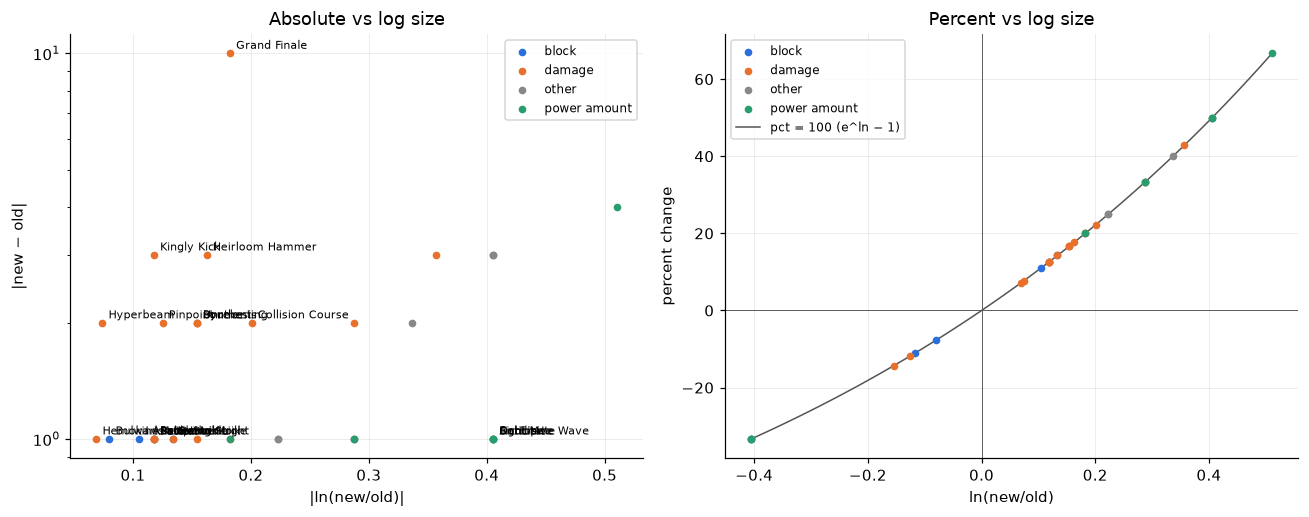

In [7]:
GAP = 8
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for kd, g in R.groupby("kind"):
    ax.scatter(g.ln.abs(), g.delta.abs(), color=KIND_C.get(kd, GREY), label=kd, zorder=3)
for _, r in R[R.gap.abs() >= GAP].iterrows():
    ax.annotate(r.card_id.replace("_", " ").title(), (abs(r.ln), abs(r.delta)), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set(xlabel="|ln(new/old)|", ylabel="|new − old|", title="Absolute vs log size", yscale="log")
ax.legend(fontsize=8)
ax = axes[1]
for kd, g in R.groupby("kind"):
    ax.scatter(g.ln, g.pct, color=KIND_C.get(kd, GREY), label=kd, zorder=3)
xs = np.linspace(R.ln.min(), R.ln.max(), 100)
ax.plot(xs, 100 * (np.exp(xs) - 1), color=GREY, lw=1, label="pct = 100 (e^ln − 1)")
ax.axhline(0, color=GREY, lw=0.6)
ax.axvline(0, color=GREY, lw=0.6)
ax.set(xlabel="ln(new/old)", ylabel="percent change", title="Percent vs log size")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Effects next to doses (needs notebook 02's saved fits)

If `data/analysis/did_h3.parquet` exists, each tweak's measured effect is added: `beta_pp` is
the change in pick rate in percentage points (clustered error bar `se_pp`), and `beta_lo` is
the same on the log-odds scale. `toward` says whether the effect has the same sign as the
change (a buff that raised picks, or a nerf that lowered them); this is a sign check, not a
test of size. Rows are in the same order as section 1. The full table is also saved to
`data/analysis/tweak_ledger.csv` for opening in a spreadsheet (that folder is git-ignored).

In [8]:
H_PATH = OUT / "did_h3.parquet"
LED = LL[["card_id", "color", "patch", "kind", "main_field", "old", "new", "delta", "pct", "ln",
          "change", "solo", "mixed", "upg_only", "changed", "also_upgrade", "scaling_var",
          "multi_field", "note"]].copy()
if H_PATH.exists():
    H = pd.read_parquet(H_PATH)
    if "card_patch_id" in H.columns:
        H = H.set_index("card_patch_id")
    H = H[H.error == ""] if "error" in H.columns else H
    eff = pd.DataFrame(index=H.index)
    eff["beta_pp"] = 100 * pd.to_numeric(H.beta, errors="coerce")
    eff["se_pp"] = 100 * pd.to_numeric(H.se, errors="coerce")
    eff["beta_lo"] = pd.to_numeric(H.beta_lo, errors="coerce")
    eff["se_lo"] = pd.to_numeric(H.se_lo, errors="coerce")
    LED = LED.join(eff)
    LED["toward"] = np.where(LED.beta_pp.isna() | (LED.ln == 0) | LED.ln.isna(), "",
                             np.where(np.sign(LED.beta_pp) == np.sign(LED.ln), "yes", "no"))
    show = ["card_id", "patch", "kind", "old", "new", "pct", "ln", "change", "beta_pp", "se_pp",
            "beta_lo", "toward", "solo", "mixed", "upg_only"]
    display(LED.dropna(subset=["beta_pp"]).sort_values(["patch", "ln"], ascending=[False, True])
            [show].round(3))
    print(pd.crosstab(LED.patch, LED.toward).drop(columns="", errors="ignore").to_string())
else:
    print(f"{H_PATH.name} not found: showing doses only. Run notebook 02 (section 6b) for effects.")
LED.to_csv(OUT / "tweak_ledger.csv")
print("saved", (OUT / "tweak_ledger.csv").relative_to(ROOT), f"({len(LED)} rows)")

,card_id,patch,kind,old,new,pct,ln,change,beta_pp,se_pp,beta_lo,toward,solo,mixed,upg_only
card_patch_id,,,,,,,,,,,,,,,
DEBILITATE@v0.107.1/patch,DEBILITATE,second,power amount,3,2,-33.333,-0.406,nerf,2.225,0.879,0.118,no,yes,no,no
REFLECT@v0.107.1/patch,REFLECT,second,block,17,15,-11.765,-0.125,nerf,3.441,1.026,0.139,no,yes,yes,no
PATTER@v0.107.1/patch,PATTER,second,block,9,8,-11.111,-0.118,nerf,-3.300,0.669,-0.171,yes,yes,no,no
BULWARK@v0.107.1/patch,BULWARK,second,block,13,12,-7.692,-0.080,nerf,2.300,1.086,0.092,no,yes,no,no
HYPERBEAM@v0.107.1/patch,HYPERBEAM,second,damage,26,28,7.692,0.074,buff,-0.555,0.872,-0.057,no,yes,no,no
POUNCE@v0.107.1/patch,POUNCE,second,damage,12,14,16.667,0.154,buff,1.885,0.642,0.146,yes,yes,no,no
SYNTHESIS@v0.107.1/patch,SYNTHESIS,second,damage,12,14,16.667,0.154,buff,0.910,0.660,0.081,yes,yes,no,no
UNRELENTING@v0.107.1/patch,UNRELENTING,second,damage,12,14,16.667,0.154,buff,4.286,0.769,0.244,yes,yes,no,no
UPROAR@v0.107.1/patch,UPROAR,second,damage,5,6,20.000,0.182,buff,2.290,0.416,0.291,yes,yes,no,no


toward  no  yes
patch          
first    5   20
second   8    7
saved data/analysis/tweak_ledger.csv (50 rows)


## 6. What the dose doesn't capture

The dose is one number per card. It does not see cost changes, text-only changes, or anything on
a card that changed in a way no number captures. For scaling cards (`scaling_var`, section 2)
the printed damage is a base value, so the dose may mean something different there.